# Handwritten Digit Classification Using Gradient Descent

Softmax Regression on MNIST, trained with Gradient Descent implemented from scratch in NumPy.

**Notebook outline:** load data, check the gradients, train, compare learning rates, evaluate, inspect mistakes, save weights for the Streamlit demo.

Math recap (N examples, 10 classes):
- scores `z = Wx + b`, probabilities `p = softmax(z)`
- loss `J = -(1/N) Σ log p[i, y_i]`
- gradients `dJ/dW = (1/N)(P - Y)ᵀX`, `dJ/db = (1/N) Σ(P - Y)`
- update `W ← W - α ∇_W J`, `b ← b - α ∇_b J`

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # so `src` can be imported from notebooks/

import numpy as np
import matplotlib.pyplot as plt

from src.data import load_data
from src.model import SoftmaxClassifier
from src.train import train, lr_sweep, best_by_val_acc
from src.gradcheck import gradient_check
from src.evaluate import (evaluate, plot_loss_curves, plot_accuracy_comparison,
                          plot_confusion_matrix, plot_predictions, plot_weight_templates)

DATASET = os.environ.get("DIGIT_DATASET", "mnist")   # "mnist" is the real project; "digits" is a tiny offline test set
EPOCHS = int(os.environ.get("DIGIT_EPOCHS", 100))
LEARNING_RATES = [0.01, 0.1, 0.5, 2.0, 8.0]
SEED = 0

## 1. Load and prepare the data
Pixels are scaled to 0-1 and flattened to 784 features. MNIST is split into 50,000 train, 10,000 validation and 10,000 test images. The first run downloads MNIST once and caches it in `data/`.

{'X_train': (50000, 784), 'y_train': (50000,), 'X_val': (10000, 784), 'y_val': (10000,), 'X_test': (10000, 784), 'y_test': (10000,)}


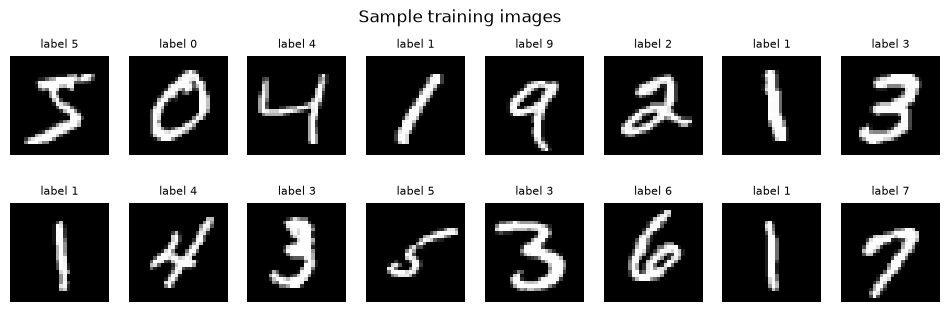

In [2]:
data = load_data(DATASET, seed=SEED)
print({k: v.shape for k, v in data.items() if k != "image_shape"})

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, label in zip(axes.ravel(), data["X_train"], data["y_train"]):
    ax.imshow(img.reshape(data["image_shape"]), cmap="gray")
    ax.set_title(f"label {label}", fontsize=8)
    ax.axis("off")
plt.suptitle("Sample training images")
plt.show()

## 2. Verify the gradients
Before training, compare the analytic gradients with numerical ones (central differences). A relative error around 1e-7 or smaller means the derivation and code agree.

In [3]:
err = gradient_check(data["X_train"], data["y_train"])
print(f"relative error between analytic and numerical gradients: {err:.2e}")
assert err < 1e-6, "Gradients look wrong"

untrained = SoftmaxClassifier(data["X_train"].shape[1], 10, seed=SEED)
print(f"loss of an untrained model: {untrained.loss(data['X_val'], data['y_val']):.4f}   (ln 10 = {np.log(10):.4f})")

relative error between analytic and numerical gradients: 1.70e-10
loss of an untrained model: 2.3058   (ln 10 = 2.3026)


## 3. Baseline training run

In [4]:
model, hist = train(data, lr=0.5, epochs=EPOCHS, seed=SEED, verbose=True)
print(f"validation accuracy: {hist['val_acc'][-1]:.4f}")

  lr=0.5     epoch    1/100  loss 2.3055  val_acc 0.6688
  lr=0.5     epoch   11/100  loss 0.7891  val_acc 0.8595
  lr=0.5     epoch   21/100  loss 0.6092  val_acc 0.8791
  lr=0.5     epoch   31/100  loss 0.5352  val_acc 0.8864
  lr=0.5     epoch   41/100  loss 0.4928  val_acc 0.8901
  lr=0.5     epoch   51/100  loss 0.4647  val_acc 0.8942
  lr=0.5     epoch   61/100  loss 0.4443  val_acc 0.8973
  lr=0.5     epoch   71/100  loss 0.4286  val_acc 0.9001
  lr=0.5     epoch   81/100  loss 0.4161  val_acc 0.9022
  lr=0.5     epoch   91/100  loss 0.4058  val_acc 0.9043
  lr=0.5     epoch  100/100  loss 0.3980  val_acc 0.9056
validation accuracy: 0.9056


## 4. Learning-rate comparison
All runs share the same data split, initial parameters (same seed) and number of epochs, so only the learning rate differs.

lr      final train loss    final val acc  
0.01    1.5622              0.7888         
0.1     0.6180              0.8778         
0.5     0.3980              0.9056         
2       0.5149              0.8634         
8       1.6277              0.8457         


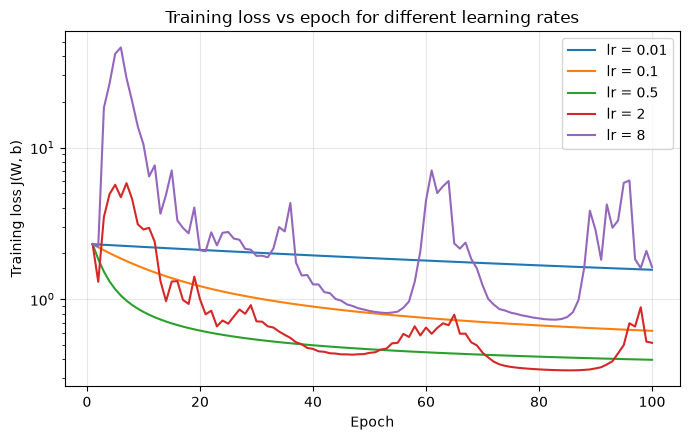

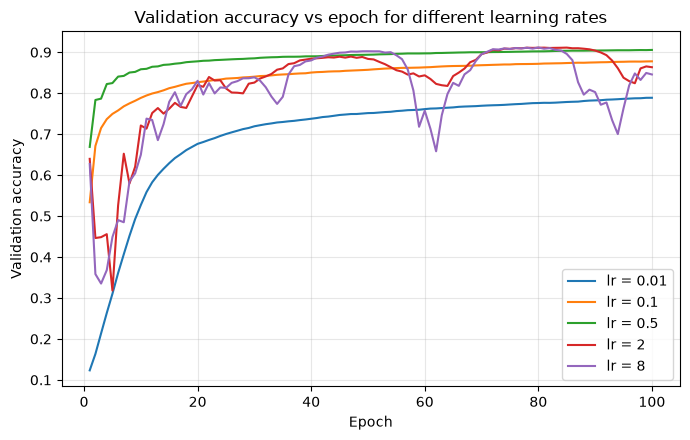

In [5]:
results = lr_sweep(data, LEARNING_RATES, epochs=EPOCHS, seed=SEED)

print(f"{'lr':<8}{'final train loss':<20}{'final val acc':<15}")
for lr, (_, h) in results.items():
    print(f"{lr:<8g}{h['train_loss'][-1]:<20.4f}{h['val_acc'][-1]:<15.4f}")

plot_loss_curves(results, "../results/loss_curves.png")
plot_accuracy_comparison(results, "../results/accuracy_comparison.png")
plt.show()

### Observations
All five runs used the same data split, the same initial weights (seed 0) and 100 epochs, so only the learning rate differs.

| lr | final train loss | final val acc |
|---|---|---|
| 0.01 | 1.5622 | 0.7888 |
| 0.1 | 0.6180 | 0.8778 |
| 0.5 | 0.3980 | 0.9056 |
| 2 | 0.5149 | 0.8634 |
| 8 | 1.6277 | 0.8457 |

- **Too small a learning rate (0.01):** the loss decreases smoothly but very slowly. After 100 epochs it is still 1.56 (it started at about ln 10 = 2.30) and validation accuracy is only 0.789. The steps are too small to make real progress in 100 updates.
- **A good learning rate (0.5, and 0.1):** the loss falls quickly in the first ~20 epochs and then keeps decreasing smoothly with no jumps. 0.5 reaches the lowest final loss (0.398) and the best final validation accuracy (0.906). 0.1 follows the same smooth shape but is slower (0.618, 0.878).
- **Too large a learning rate (2 and 8):** the loss jumps up in the first few epochs (above 40 for lr = 8, about 6 for lr = 2) instead of going down, then partly recovers and spikes again several times (lr = 8 around epochs 35, 60 and 90; lr = 2 around epochs 55-65 and 90-100). The steps overshoot the minimum, so Gradient Descent oscillates instead of converging. Validation accuracy shows the same instability, for example lr = 8 drops to about 0.66 near epoch 62.
- Interestingly, lr = 2 and lr = 8 briefly reach about 0.91 validation accuracy (around epochs 75-85), slightly above lr = 0.5 at that point, but they do not stay there. Their final values (0.863 and 0.846) are worse, so they cannot be trusted.
- **Best learning rate:** 0.5, chosen by final validation accuracy. It is the largest rate tested that still decreases the loss at every epoch: big enough to move fast, small enough not to overshoot.

## 5. Final evaluation on the test set
The learning rate is chosen using validation accuracy only. The test set is used once, at the end.

best learning rate (by validation accuracy): 0.5
test accuracy: 0.9026    test loss: 0.3720


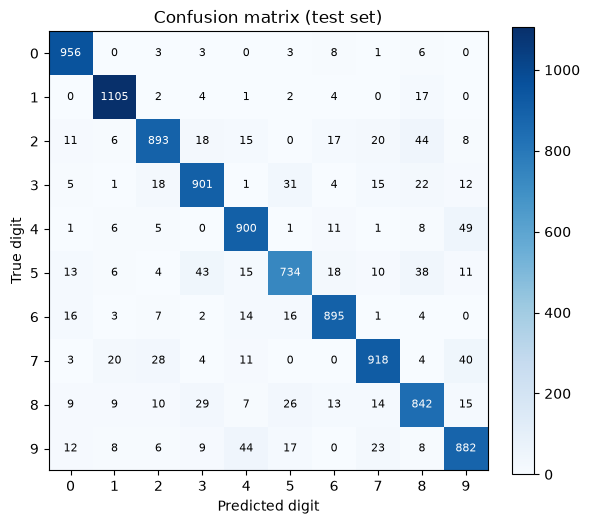

In [6]:
best_lr, best_model, _ = best_by_val_acc(results)
test = evaluate(best_model, data["X_test"], data["y_test"])
print(f"best learning rate (by validation accuracy): {best_lr:g}")
print(f"test accuracy: {test['accuracy']:.4f}    test loss: {test['loss']:.4f}")

plot_confusion_matrix(test["confusion_matrix"], "../results/confusion_matrix.png")
plt.show()

In [7]:
cm = test["confusion_matrix"].copy()
np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1][:5], cm.shape))[0]
print("Most common confusions (true -> predicted : count)")
for t, p in top:
    print(f"  {t} -> {p} : {cm[t, p]}")

Most common confusions (true -> predicted : count)
  4 -> 9 : 49
  9 -> 4 : 44
  2 -> 8 : 44
  5 -> 3 : 43
  7 -> 9 : 40


## 6. Look at predictions and mistakes

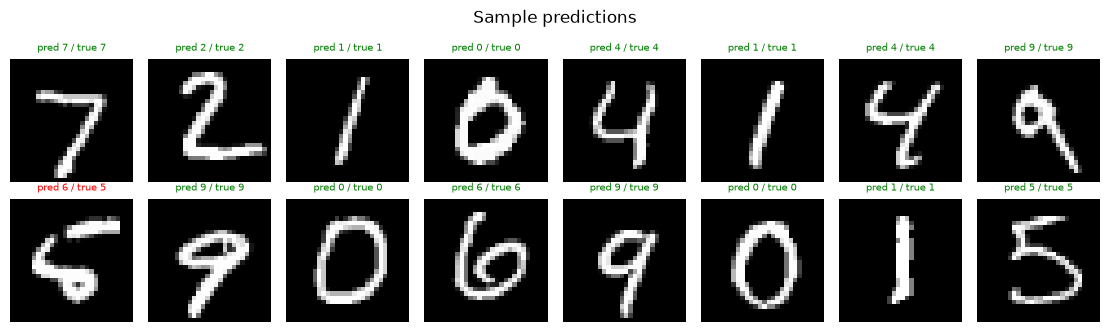

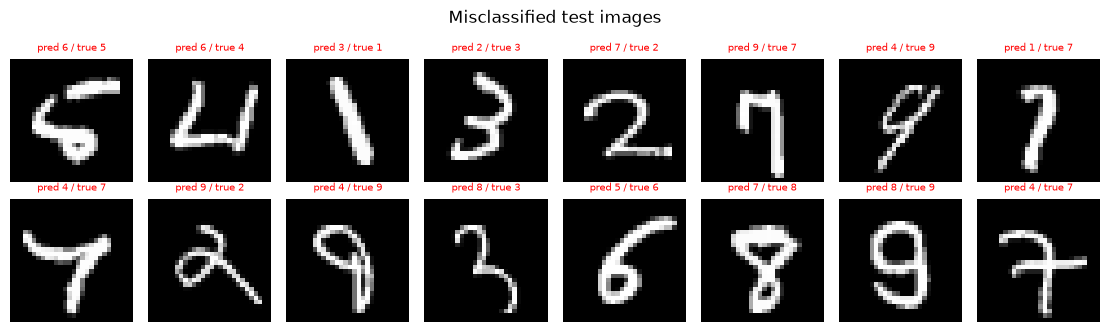

In [8]:
plot_predictions(best_model, data["X_test"], data["y_test"], data["image_shape"], n=16)
plot_predictions(best_model, data["X_test"], data["y_test"], data["image_shape"], n=16, only_wrong=True)
plt.show()

## 7. What did the model learn?
Each row of `W` has one weight per pixel. Red pixels raise the score for that digit, blue pixels lower it.

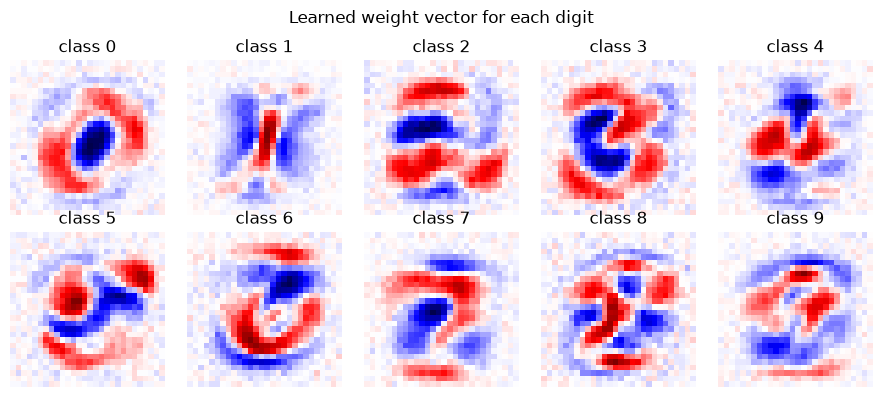

In [9]:
plot_weight_templates(best_model, data["image_shape"], "../results/weight_templates.png")
plt.show()

## 8. Save the trained model for the Streamlit demo

In [10]:
if DATASET == "mnist":
    best_model.save("../results/weights.npz")
    print("saved results/weights.npz  ->  now run:  streamlit run app.py")
else:
    print("Skipped saving: the Streamlit demo needs a model trained on 28x28 MNIST.")

saved results/weights.npz  ->  now run:  streamlit run app.py


## Conclusions
- **Gradients are correct.** The analytic gradients matched finite-difference gradients with a relative error of 1.70e-10, and the untrained model's loss was 2.3058, close to ln 10 = 2.3026, as expected for 10 equally likely classes.
- **The learning rate controls convergence.** With the same data, initial weights and 100 epochs: 0.01 was too slow (val acc 0.789), 0.5 converged smoothly and gave the best result (val acc 0.906), and 2 and 8 overshot, so the loss oscillated with large spikes (final val acc 0.863 and 0.846).
- **Final result.** The model with lr = 0.5 reached a test accuracy of 0.9026 (test loss 0.3720) on 10,000 unseen test images. The test set was used once, after choosing the learning rate on the validation set.
- **Where the model makes mistakes.** The most common confusions were 4 -> 9 (49 images), 9 -> 4 (44), 2 -> 8 (44), 5 -> 3 (43) and 7 -> 9 (40). These pairs have similar shapes; for example 4 and 9 differ mainly in whether the top is closed.
- **What the model learned.** Each row of W, shown as a 28 x 28 image, looks like a rough template of its digit: for class 0, a red ring with a blue centre (ink in the middle counts against a 0).
- **Limitation.** Softmax Regression is a linear model: it scores each pixel separately and cannot combine pixels into strokes or shapes, which limits accuracy on digits that look alike. Training was also stopped at 100 epochs while the loss for lr = 0.5 was still slowly decreasing.
- **Calculus link.** The whole training process is the chain rule (gradient of cross-entropy through Softmax, giving (P - Y)^T X / N) plus repeated steps against the gradient, with the learning rate setting the step size.